IDC 409



In [ ]:
import os
import urllib.request
import sqlite3
from datetime import datetime

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. FOLDERS
# ============================================================

KNOWN_DIR = "known_faces"
TEST_DIR = "test_images"
OUTPUT_DIR = "output"
DB_DIR = "database"
MODEL_DIR = "models"

os.makedirs(KNOWN_DIR, exist_ok=True)
os.makedirs(TEST_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(DB_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)


# ============================================================
# 2. MODEL DOWNLOAD
# ============================================================

YUNET_URL = (
    "https://huggingface.co/opencv/face_detection_yunet/"
    "resolve/main/face_detection_yunet_2023mar.onnx"
)

SFACE_URL = (
    "https://huggingface.co/opencv/face_recognition_sface/"
    "resolve/main/face_recognition_sface_2021dec.onnx"
)

YUNET_MODEL = os.path.join(
    MODEL_DIR,
    "face_detection_yunet_2023mar.onnx"
)

SFACE_MODEL = os.path.join(
    MODEL_DIR,
    "face_recognition_sface_2021dec.onnx"
)


def download_model(url, filename):
    if not os.path.exists(filename):
        print("\nDownloading:")
        print(filename)
        print("Please wait...")

        urllib.request.urlretrieve(url, filename)

        print("Download completed.")

    else:
        print("Model already exists:", filename)


download_model(YUNET_URL, YUNET_MODEL)
download_model(SFACE_URL, SFACE_MODEL)


# ============================================================
# 3. CHECK OPENCV
# ============================================================

print("\nOpenCV version:", cv2.__version__)

if not hasattr(cv2, "FaceRecognizerSF"):
    raise RuntimeError(
        "\nYour OpenCV installation does not contain FaceRecognizerSF.\n"
        "Run:\n"
        "python -m pip uninstall opencv-python opencv-contrib-python -y\n"
        "python -m pip install opencv-contrib-python==4.10.0.84\n"
    )


# ============================================================
# 4. CREATE FACE DETECTOR AND RECOGNIZER
# ============================================================

detector = cv2.FaceDetectorYN.create(
    YUNET_MODEL,
    "",
    (320, 320),
    0.85,
    0.30,
    5000
)

recognizer = cv2.FaceRecognizerSF.create(
    SFACE_MODEL,
    ""
)

# OpenCV's documented SFace cosine threshold
COSINE_THRESHOLD = 0.363


# ============================================================
# 5. FACE DETECTION FUNCTION
# ============================================================

def detect_faces(image):

    if image is None:
        return None

    height, width = image.shape[:2]

    detector.setInputSize((width, height))

    _, faces = detector.detect(image)

    return faces


# ============================================================
# 6. GET FACE EMBEDDING
# ============================================================

def get_embedding(image, face):

    # Align and crop the face
    aligned_face = recognizer.alignCrop(
        image,
        face
    )

    # Generate SFace embedding
    feature = recognizer.feature(
        aligned_face
    )

    return feature


# ============================================================
# 7. LOAD KNOWN FACES
# ============================================================

def load_known_faces():

    known_features = []
    known_names = []

    print("\n===================================")
    print("LOADING KNOWN FACES")
    print("===================================")

    if not os.path.exists(KNOWN_DIR):
        print("known_faces folder does not exist.")
        return known_features, known_names

    people = os.listdir(KNOWN_DIR)

    for person in people:

        person_folder = os.path.join(
            KNOWN_DIR,
            person
        )

        if not os.path.isdir(person_folder):
            continue

        print("\nStudent:", person)

        files = os.listdir(person_folder)

        image_count = 0

        for filename in files:

            if not filename.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp")
            ):
                continue

            image_path = os.path.join(
                person_folder,
                filename
            )

            image = cv2.imread(image_path)

            if image is None:
                print("Cannot read:", filename)
                continue

            faces = detect_faces(image)

            if faces is None or len(faces) == 0:

                print(
                    "NO FACE DETECTED:",
                    filename
                )

                continue

            # Use the largest detected face
            face = max(
                faces,
                key=lambda f: f[2] * f[3]
            )

            try:

                feature = get_embedding(
                    image,
                    face
                )

                known_features.append(feature)
                known_names.append(person)

                image_count += 1

                print(
                    "Loaded:",
                    filename
                )

            except Exception as e:

                print(
                    "Embedding failed:",
                    filename,
                    e
                )

        print(
            "Usable images:",
            image_count
        )

    print("\nTotal embeddings:", len(known_features))

    return known_features, known_names


# ============================================================
# 8. RECOGNIZE ONE FACE
# ============================================================

def recognize_face(
    image,
    face,
    known_features,
    known_names
):

    if len(known_features) == 0:

        return "UNKNOWN", 0.0

    query_feature = get_embedding(
        image,
        face
    )

    best_score = -1
    best_name = "UNKNOWN"

    for feature, name in zip(
        known_features,
        known_names
    ):

        score = recognizer.match(
            query_feature,
            feature,
            cv2.FaceRecognizerSF_FR_COSINE
        )

        score = float(score)

        if score > best_score:

            best_score = score
            best_name = name

    if best_score >= COSINE_THRESHOLD:

        return best_name, best_score

    else:

        return "UNKNOWN", best_score


# ============================================================
# 9. PROCESS TEST IMAGE
# ============================================================

def process_test_image(
    image_path,
    known_features,
    known_names
):

    print("\n===================================")
    print("PROCESSING TEST IMAGE")
    print("===================================")

    print("Image:", image_path)

    image = cv2.imread(image_path)

    if image is None:

        print("ERROR: Could not read image.")

        return None

    faces = detect_faces(image)

    if faces is None or len(faces) == 0:

        print("NO FACES DETECTED.")

        return image

    print(
        "Number of faces detected:",
        len(faces)
    )

    attendance_rows = []

    for i, face in enumerate(faces):

        try:

            name, score = recognize_face(
                image,
                face,
                known_features,
                known_names
            )

        except Exception as e:

            print(
                "Recognition error:",
                e
            )

            name = "UNKNOWN"
            score = 0.0

        x = int(face[0])
        y = int(face[1])
        w = int(face[2])
        h = int(face[3])

        # Draw bounding box
        if name == "UNKNOWN":

            box_color = (0, 0, 255)

        else:

            box_color = (0, 255, 0)

        cv2.rectangle(
            image,
            (x, y),
            (x + w, y + h),
            box_color,
            2
        )

        label = f"{name} ({score:.2f})"

        cv2.putText(
            image,
            label,
            (x, max(20, y - 10)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            box_color,
            2
        )

        print(
            f"Face {i + 1}: {name}, "
            f"score = {score:.3f}"
        )

        if name != "UNKNOWN":

            now = datetime.now()

            attendance_rows.append(
                {
                    "Name": name,
                    "Date": now.strftime(
                        "%Y-%m-%d"
                    ),
                    "Time": now.strftime(
                        "%H:%M:%S"
                    ),
                    "Similarity": round(
                        score,
                        4
                    )
                }
            )

    # Save annotated image
    output_image = os.path.join(
        OUTPUT_DIR,
        "recognized_result.jpg"
    )

    cv2.imwrite(
        output_image,
        image
    )

    print(
        "\nResult saved:",
        output_image
    )

    # Display
    image_rgb = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    plt.figure(
        figsize=(12, 8)
    )

    plt.imshow(image_rgb)
    plt.axis("off")
    plt.title("Face Recognition Result")

    plt.show()

    return attendance_rows


# ============================================================
# 10. SAVE ATTENDANCE TO CSV
# ============================================================

def save_to_csv(attendance_rows):

    csv_path = os.path.join(
        OUTPUT_DIR,
        "attendance.csv"
    )

    if len(attendance_rows) == 0:

        print(
            "\nNo recognized students."
        )

        return

    new_data = pd.DataFrame(
        attendance_rows
    )

    # Avoid duplicate attendance for same
    # person on same date
    if os.path.exists(csv_path):

        old_data = pd.read_csv(
            csv_path
        )

        combined = pd.concat(
            [old_data, new_data],
            ignore_index=True
        )

        combined = combined.drop_duplicates(
            subset=["Name", "Date"],
            keep="first"
        )

    else:

        combined = new_data

    combined.to_csv(
        csv_path,
        index=False
    )

    print(
        "\nAttendance CSV saved:",
        csv_path
    )

    print("\nAttendance:")
    print(combined)


# ============================================================
# 11. SQLITE DATABASE
# ============================================================

DB_PATH = os.path.join(
    DB_DIR,
    "attendance.db"
)


def create_database():

    connection = sqlite3.connect(
        DB_PATH
    )

    cursor = connection.cursor()

    cursor.execute(
        """
        CREATE TABLE IF NOT EXISTS attendance (
            id INTEGER PRIMARY KEY AUTOINCREMENT,
            name TEXT NOT NULL,
            date TEXT NOT NULL,
            time TEXT NOT NULL,
            similarity REAL
        )
        """
    )

    connection.commit()

    return connection


def save_to_database(attendance_rows):

    connection = create_database()

    cursor = connection.cursor()

    for row in attendance_rows:

        # Check whether already present
        cursor.execute(
            """
            SELECT id
            FROM attendance
            WHERE name = ?
            AND date = ?
            """,
            (
                row["Name"],
                row["Date"]
            )
        )

        existing = cursor.fetchone()

        if existing is None:

            cursor.execute(
                """
                INSERT INTO attendance
                (name, date, time, similarity)
                VALUES (?, ?, ?, ?)
                """,
                (
                    row["Name"],
                    row["Date"],
                    row["Time"],
                    row["Similarity"]
                )
            )

    connection.commit()

    print(
        "\nAttendance saved to SQLite database."
    )

    # READ DATABASE
    database_df = pd.read_sql_query(
        """
        SELECT *
        FROM attendance
        """,
        connection
    )

    print("\nDATABASE CONTENT:")
    print(database_df)

    connection.close()


# ============================================================
# 12. EDA - IMAGE COUNT
# ============================================================

def perform_eda():

    print("\n===================================")
    print("EDA")
    print("===================================")

    data = []

    for person in os.listdir(KNOWN_DIR):

        person_folder = os.path.join(
            KNOWN_DIR,
            person
        )

        if not os.path.isdir(person_folder):
            continue

        for filename in os.listdir(
            person_folder
        ):

            if not filename.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp")
            ):
                continue

            path = os.path.join(
                person_folder,
                filename
            )

            image = cv2.imread(path)

            if image is None:
                continue

            height, width = image.shape[:2]

            gray = cv2.cvtColor(
                image,
                cv2.COLOR_BGR2GRAY
            )

            brightness = float(
                np.mean(gray)
            )

            faces = detect_faces(image)

            if faces is None:
                face_detected = 0
            else:
                face_detected = len(faces)

            data.append(
                {
                    "Person": person,
                    "Filename": filename,
                    "Width": width,
                    "Height": height,
                    "Brightness": brightness,
                    "Faces_Detected": face_detected
                }
            )

    if len(data) == 0:

        print(
            "No images found for EDA."
        )

        return

    df = pd.DataFrame(data)

    # Save EDA data
    eda_csv = os.path.join(
        OUTPUT_DIR,
        "eda_results.csv"
    )

    df.to_csv(
        eda_csv,
        index=False
    )

    print(
        "\nEDA data saved:",
        eda_csv
    )

    print("\nEDA DATA:")
    print(df)

    # --------------------------------------------------------
    # GRAPH 1: IMAGES PER PERSON
    # --------------------------------------------------------

    counts = (
        df["Person"]
        .value_counts()
    )

    plt.figure(
        figsize=(8, 5)
    )

    counts.plot(
        kind="bar"
    )

    plt.title(
        "Number of Images per Person"
    )

    plt.xlabel(
        "Person"
    )

    plt.ylabel(
        "Number of Images"
    )

    plt.tight_layout()

    plt.show()

    # --------------------------------------------------------
    # GRAPH 2: BRIGHTNESS
    # --------------------------------------------------------

    plt.figure(
        figsize=(8, 5)
    )

    plt.hist(
        df["Brightness"],
        bins=10
    )

    plt.title(
        "Lighting / Brightness Distribution"
    )

    plt.xlabel(
        "Average Pixel Intensity"
    )

    plt.ylabel(
        "Number of Images"
    )

    plt.tight_layout()

    plt.show()

    # --------------------------------------------------------
    # GRAPH 3: FACE DETECTION
    # --------------------------------------------------------

    successful = (
        df["Faces_Detected"] > 0
    ).sum()

    failed = (
        df["Faces_Detected"] == 0
    ).sum()

    detection_data = pd.Series(
        {
            "Successful": successful,
            "Failed": failed
        }
    )

    plt.figure(
        figsize=(6, 5)
    )

    detection_data.plot(
        kind="bar"
    )

    plt.title(
        "Successful vs Failed Face Detection"
    )

    plt.xlabel(
        "Detection Result"
    )

    plt.ylabel(
        "Number of Images"
    )

    plt.tight_layout()

    plt.show()

    print("\nSuccessful detections:", successful)
    print("Failed detections:", failed)


# ============================================================
# 13. MAIN PROGRAM
# ============================================================

print("\n")
print("==========================================")
print("     IDC409 FACE ATTENDANCE SYSTEM")
print("==========================================")

print("\nFolder structure required:")
print(
    """
known_faces/
    Student_A/
        image1.jpg
        image2.jpg
        image3.jpg

    Student_B/
        image1.jpg
        image2.jpg
        image3.jpg

test_images/
    classroom.jpg
"""
)

# Load known faces
known_features, known_names = load_known_faces()

if len(known_features) == 0:

    print(
        "\nNO KNOWN FACE EMBEDDINGS FOUND."
    )

    print(
        "\nPlease put student images inside:"
    )

    print(
        "known_faces/Student_Name/"
    )

    print(
        "\nThen run the program again."
    )

else:

    # EDA
    perform_eda()

    # Find first test image
    test_files = []

    for filename in os.listdir(
        TEST_DIR
    ):

        if filename.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp")
        ):

            test_files.append(filename)

    if len(test_files) == 0:

        print(
            "\nNo test image found."
        )

        print(
            "Put a classroom/test image inside:"
        )

        print(
            "test_images/"
        )

    else:

        test_image_path = os.path.join(
            TEST_DIR,
            test_files[0]
        )

        attendance = process_test_image(
            test_image_path,
            known_features,
            known_names
        )

        if attendance:

            save_to_csv(
                attendance
            )

            save_to_database(
                attendance
            )

print("\n==========================================")
print("PROGRAM FINISHED")
print("==========================================")


Downloading:
models/face_detection_yunet_2023mar.onnx
Please wait...
Download completed.

Downloading:
models/face_recognition_sface_2021dec.onnx
Please wait...
Download completed.

OpenCV version: 4.14.0


     IDC409 FACE ATTENDANCE SYSTEM

Folder structure required:

known_faces/
    Student_A/
        image1.jpg
        image2.jpg
        image3.jpg

    Student_B/
        image1.jpg
        image2.jpg
        image3.jpg

test_images/
    classroom.jpg


LOADING KNOWN FACES

Total embeddings: 0

NO KNOWN FACE EMBEDDINGS FOUND.

Please put student images inside:
known_faces/Student_Name/

Then run the program again.

PROGRAM FINISHED


In [ ]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFolders:")
print(os.listdir())

Current folder:
/content

Folders:
['.config', 'models', 'known_faces', 'test_images', 'lfw_data', 'output', 'database', 'sample_data']


In [ ]:
import os

os.makedirs("/content/known_faces/Student_A", exist_ok=True)
os.makedirs("/content/known_faces/Student_B", exist_ok=True)
os.makedirs("/content/test_images", exist_ok=True)

print("Folders created!")

Folders created!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive.zip


In [ ]:
import zipfile
import os

ZIP_PATH = "/content/archive.zip"

print("Checking ZIP file...")

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:

    files = zip_ref.namelist()

    print("Total files in ZIP:", len(files))

    print("\nFirst 30 files/folders:")
    for item in files[:30]:
        print(item)

Checking ZIP file...
Total files in ZIP: 13243

First 30 files/folders:
lfw-deepfunneled/lfw-deepfunneled/AJ_Cook/AJ_Cook_0001.jpg
lfw-deepfunneled/lfw-deepfunneled/AJ_Lamas/AJ_Lamas_0001.jpg
lfw-deepfunneled/lfw-deepfunneled/Aaron_Eckhart/Aaron_Eckhart_0001.jpg
lfw-deepfunneled/lfw-deepfunneled/Aaron_Guiel/Aaron_Guiel_0001.jpg
lfw-deepfunneled/lfw-deepfunneled/Aaron_Patterson/Aaron_Patterson_0001.jpg
lfw-deepfunneled/lfw-deepfunneled/Aaron_Peirsol/Aaron_Peirsol_0001.jpg
lfw-deepfunneled/lfw-deepfunneled/Aaron_Peirsol/Aaron_Peirsol_0002.jpg
lfw-deepfunneled/lfw-deepfunneled/Aaron_Peirsol/Aaron_Peirsol_0003.jpg
lfw-deepfunneled/lfw-deepfunneled/Aaron_Peirsol/Aaron_Peirsol_0004.jpg
lfw-deepfunneled/lfw-deepfunneled/Aaron_Pena/Aaron_Pena_0001.jpg
lfw-deepfunneled/lfw-deepfunneled/Aaron_Sorkin/Aaron_Sorkin_0001.jpg
lfw-deepfunneled/lfw-deepfunneled/Aaron_Sorkin/Aaron_Sorkin_0002.jpg
lfw-deepfunneled/lfw-deepfunneled/Aaron_Tippin/Aaron_Tippin_0001.jpg
lfw-deepfunneled/lfw-deepfunneled/Abba_

In [ ]:
import zipfile
import os

EXTRACT_PATH = "/content/lfw_data"

os.makedirs(EXTRACT_PATH, exist_ok=True)

with zipfile.ZipFile("/content/archive.zip", "r") as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)

print("✅ Dataset extracted successfully!")

print("\nFolders/files inside lfw_data:")
print(os.listdir(EXTRACT_PATH))

✅ Dataset extracted successfully!

Folders/files inside lfw_data:
['lfw-deepfunneled', 'pairs.csv', 'mismatchpairsDevTrain.csv', 'matchpairsDevTrain.csv', 'peopleDevTest.csv', 'people.csv', 'mismatchpairsDevTest.csv', 'lfw_readme.csv', 'peopleDevTrain.csv', 'lfw_allnames.csv', 'matchpairsDevTest.csv']


In [ ]:
import os

print("Searching for folders containing face images...\n")

for root, dirs, files in os.walk("/content/lfw_data"):

    image_files = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    if len(image_files) > 0:

        print("Folder:", root)
        print("Number of images here:", len(image_files))
        print("Example:", image_files[:3])
        print("-" * 50)

Streaming output truncated to the last 5000 lines.
Folder: /content/lfw_data/lfw-deepfunneled/lfw-deepfunneled/Gonzalo_Barrientos
Number of images here: 1
Example: ['Gonzalo_Barrientos_0001.jpg']
--------------------------------------------------
Folder: /content/lfw_data/lfw-deepfunneled/lfw-deepfunneled/Eli_Broad
Number of images here: 1
Example: ['Eli_Broad_0001.jpg']
--------------------------------------------------
Folder: /content/lfw_data/lfw-deepfunneled/lfw-deepfunneled/Bart_Hendricks
Number of images here: 1
Example: ['Bart_Hendricks_0001.jpg']
--------------------------------------------------
Folder: /content/lfw_data/lfw-deepfunneled/lfw-deepfunneled/Steve_Peace
Number of images here: 1
Example: ['Steve_Peace_0001.jpg']
--------------------------------------------------
Folder: /content/lfw_data/lfw-deepfunneled/lfw-deepfunneled/Salman_Khan
Number of images here: 1
Example: ['Salman_Khan_0001.jpg']
--------------------------------------------------
Folder: /content/lfw_da

In [ ]:
import os
import pandas as pd

# Correct path for YOUR dataset
LFW_PATH = "/content/lfw_data/lfw-deepfunneled/lfw-deepfunneled"

people_data = []

for person in os.listdir(LFW_PATH):

    person_path = os.path.join(LFW_PATH, person)

    if os.path.isdir(person_path):

        images = [
            f for f in os.listdir(person_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        people_data.append({
            "Person": person,
            "Image_Count": len(images)
        })

people_df = pd.DataFrame(people_data)

# Sort from highest number of images to lowest
people_df = people_df.sort_values(
    "Image_Count",
    ascending=False
).reset_index(drop=True)

print("Total people:", len(people_df))

print("\nPeople with the most images:")
print(people_df.head(20))

Total people: 5749

People with the most images:
                       Person  Image_Count
0               George_W_Bush          530
1                Colin_Powell          236
2                  Tony_Blair          144
3             Donald_Rumsfeld          121
4           Gerhard_Schroeder          109
5                Ariel_Sharon           77
6                 Hugo_Chavez           71
7           Junichiro_Koizumi           60
8               Jean_Chretien           55
9               John_Ashcroft           53
10            Serena_Williams           52
11             Jacques_Chirac           52
12             Vladimir_Putin           49
13  Luiz_Inacio_Lula_da_Silva           48
14    Gloria_Macapagal_Arroyo           44
15      Arnold_Schwarzenegger           42
16          Jennifer_Capriati           42
17                 Laura_Bush           41
18             Lleyton_Hewitt           41
19                  Hans_Blix           39


In [ ]:
selected_people = people_df[
    people_df["Image_Count"] >= 5
].head(5)

print("Selected people:")
print(selected_people.to_string(index=False))

Selected people:
           Person  Image_Count
    George_W_Bush          530
     Colin_Powell          236
       Tony_Blair          144
  Donald_Rumsfeld          121
Gerhard_Schroeder          109


In [ ]:
import os
import shutil

PROJECT_DATA = "/content/project_dataset"

# Create project dataset folder
os.makedirs(PROJECT_DATA, exist_ok=True)

for person in selected_people["Person"]:

    source_folder = os.path.join(
        LFW_PATH,
        person
    )

    destination_folder = os.path.join(
        PROJECT_DATA,
        person
    )

    os.makedirs(
        destination_folder,
        exist_ok=True
    )

    # Get image files
    images = [
        f for f in os.listdir(source_folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    # Take exactly 5
    images = sorted(images)[:5]

    for image in images:

        source = os.path.join(
            source_folder,
            image
        )

        destination = os.path.join(
            destination_folder,
            image
        )

        shutil.copy2(
            source,
            destination
        )

print("✅ Project dataset created!")

✅ Project dataset created!


In [ ]:
for person in os.listdir(PROJECT_DATA):

    folder = os.path.join(
        PROJECT_DATA,
        person
    )

    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print(person, "→", len(images), "images")

Colin_Powell → 5 images
Donald_Rumsfeld → 5 images
Gerhard_Schroeder → 5 images
Tony_Blair → 5 images
George_W_Bush → 5 images


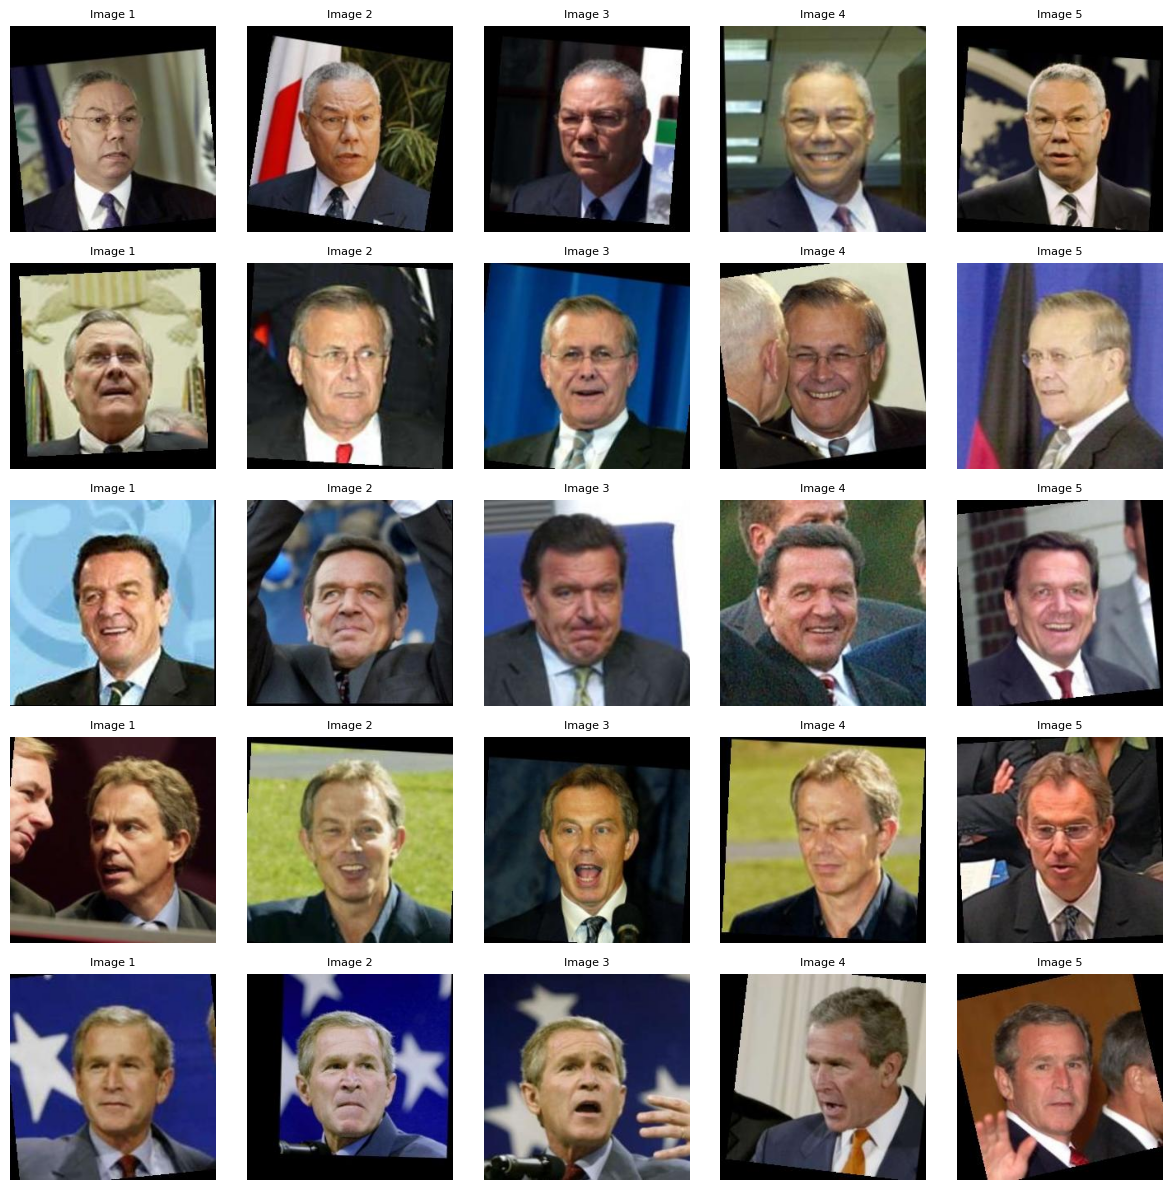

In [ ]:
import matplotlib.pyplot as plt
import cv2
import os

fig, axes = plt.subplots(
    5, 5,
    figsize=(12, 12)
)

for row, person in enumerate(
    os.listdir(PROJECT_DATA)
):

    folder = os.path.join(
        PROJECT_DATA,
        person
    )

    images = sorted(
        os.listdir(folder)
    )[:5]

    for col, filename in enumerate(images):

        path = os.path.join(
            folder,
            filename
        )

        image = cv2.imread(path)

        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        axes[row, col].imshow(image)

        if col == 0:
            axes[row, col].set_ylabel(
                person,
                fontsize=8
            )

        axes[row, col].set_title(
            f"Image {col+1}",
            fontsize=8
        )

        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os
import shutil

TRAIN_DIR = "/content/train_faces"
TEST_DIR = "/content/test_faces"

os.makedirs(TRAIN_DIR, exist_ok=True)
os.makedirs(TEST_DIR, exist_ok=True)

for person in os.listdir(PROJECT_DATA):

    source_folder = os.path.join(PROJECT_DATA, person)

    train_person = os.path.join(TRAIN_DIR, person)
    test_person = os.path.join(TEST_DIR, person)

    os.makedirs(train_person, exist_ok=True)
    os.makedirs(test_person, exist_ok=True)

    images = sorted([
        f for f in os.listdir(source_folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    # First 3 → training
    for image in images[:3]:

        shutil.copy2(
            os.path.join(source_folder, image),
            os.path.join(train_person, image)
        )

    # Last 2 → testing
    for image in images[3:5]:

        shutil.copy2(
            os.path.join(source_folder, image),
            os.path.join(test_person, image)
        )

print("TRAINING DATA")
for person in os.listdir(TRAIN_DIR):
    print(person, "→", len(os.listdir(os.path.join(TRAIN_DIR, person))))

print("\nTEST DATA")
for person in os.listdir(TEST_DIR):
    print(person, "→", len(os.listdir(os.path.join(TEST_DIR, person))))

TRAINING DATA
Colin_Powell → 3
Donald_Rumsfeld → 3
Gerhard_Schroeder → 3
Tony_Blair → 3
George_W_Bush → 3

TEST DATA
Colin_Powell → 2
Donald_Rumsfeld → 2
Gerhard_Schroeder → 2
Tony_Blair → 2
George_W_Bush → 2


In [ ]:
import cv2
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt

eda_data = []

for person in os.listdir(PROJECT_DATA):

    folder = os.path.join(PROJECT_DATA, person)

    for filename in os.listdir(folder):

        if not filename.lower().endswith(
            (".jpg", ".jpeg", ".png")
        ):
            continue

        path = os.path.join(folder, filename)

        image = cv2.imread(path)

        if image is None:
            continue

        gray = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2GRAY
        )

        brightness = float(np.mean(gray))

        height, width = image.shape[:2]

        faces = detect_faces(image)

        if faces is None:
            number_faces = 0
        else:
            number_faces = len(faces)

        eda_data.append({
            "Person": person,
            "Filename": filename,
            "Width": width,
            "Height": height,
            "Brightness": brightness,
            "Faces_Detected": number_faces
        })

eda_df = pd.DataFrame(eda_data)

print("EDA DATA")
display(eda_df)

EDA DATA


,Person,Filename,Width,Height,Brightness,Faces_Detected
0,Colin_Powell,Colin_Powell_0003.jpg,250,250,54.173568,1
1,Colin_Powell,Colin_Powell_0001.jpg,250,250,75.527696,1
2,Colin_Powell,Colin_Powell_0002.jpg,250,250,70.806112,1
3,Colin_Powell,Colin_Powell_0005.jpg,250,250,64.816464,1
4,Colin_Powell,Colin_Powell_0004.jpg,250,250,98.240752,1
5,Donald_Rumsfeld,Donald_Rumsfeld_0005.jpg,250,250,107.977200,1
6,Donald_Rumsfeld,Donald_Rumsfeld_0001.jpg,250,250,121.364608,1
7,Donald_Rumsfeld,Donald_Rumsfeld_0004.jpg,250,250,111.274096,1
8,Donald_Rumsfeld,Donald_Rumsfeld_0002.jpg,250,250,79.979296,1
9,Donald_Rumsfeld,Donald_Rumsfeld_0003.jpg,250,250,71.043344,1


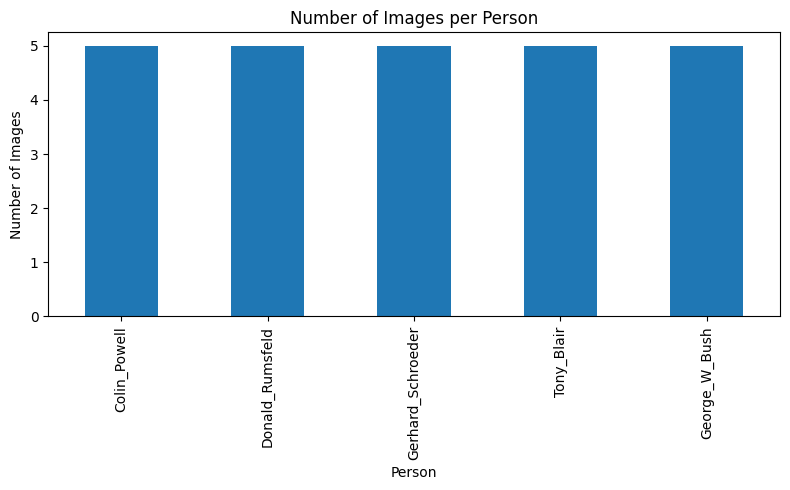

In [ ]:
plt.figure(figsize=(8,5))

eda_df["Person"].value_counts().plot(
    kind="bar"
)

plt.title("Number of Images per Person")
plt.xlabel("Person")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.show()

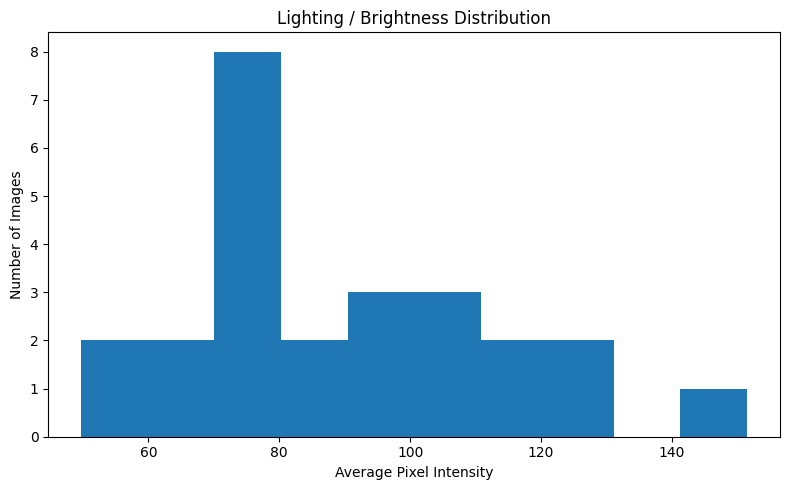

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(
    eda_df["Brightness"],
    bins=10
)

plt.title("Lighting / Brightness Distribution")
plt.xlabel("Average Pixel Intensity")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.show()

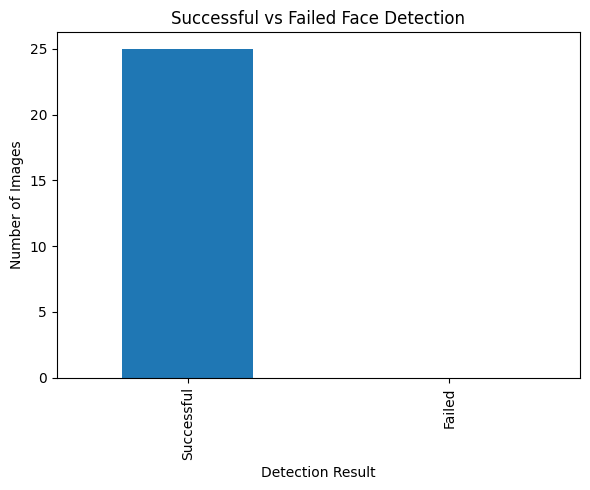

Successful detections: 25
Failed detections: 0


In [ ]:
successful = (eda_df["Faces_Detected"] > 0).sum()
failed = (eda_df["Faces_Detected"] == 0).sum()

detection_results = pd.Series({
    "Successful": successful,
    "Failed": failed
})

plt.figure(figsize=(6,5))

detection_results.plot(
    kind="bar"
)

plt.title("Successful vs Failed Face Detection")
plt.xlabel("Detection Result")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.show()

print("Successful detections:", successful)
print("Failed detections:", failed)

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd

embedding_data = []

for person in os.listdir(TRAIN_DIR):

    folder = os.path.join(TRAIN_DIR, person)

    for filename in os.listdir(folder):

        if not filename.lower().endswith(
            (".jpg", ".jpeg", ".png")
        ):
            continue

        path = os.path.join(folder, filename)

        image = cv2.imread(path)

        if image is None:
            continue

        faces = detect_faces(image)

        if faces is None or len(faces) == 0:
            print("Face not detected:", person, filename)
            continue

        # Select largest face
        face = max(
            faces,
            key=lambda f: f[2] * f[3]
        )

        try:

            feature = get_embedding(
                image,
                face
            )

            feature = feature.flatten()

            embedding_data.append({
                "Person": person,
                "Filename": filename,
                "Embedding": feature
            })

        except Exception as e:

            print(
                "Embedding failed:",
                filename,
                e
            )

print(
    "Number of successful embeddings:",
    len(embedding_data)
)

Number of successful embeddings: 15


In [ ]:
X = np.array([
    item["Embedding"]
    for item in embedding_data
])

y = np.array([
    item["Person"]
    for item in embedding_data
])

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nClasses:")
print(np.unique(y))

X shape: (15, 128)
y shape: (15,)

Classes:
['Colin_Powell' 'Donald_Rumsfeld' 'George_W_Bush' 'Gerhard_Schroeder'
 'Tony_Blair']


In [ ]:
from sklearn.svm import SVC

svm_model = SVC(
    kernel="linear",
    probability=True
)

svm_model.fit(
    X,
    y
)

print("SVM training completed!")

SVM training completed!


In [ ]:
test_data = []

for person in os.listdir(TEST_DIR):

    folder = os.path.join(TEST_DIR, person)

    for filename in os.listdir(folder):

        if not filename.lower().endswith(
            (".jpg", ".jpeg", ".png")
        ):
            continue

        path = os.path.join(folder, filename)

        image = cv2.imread(path)

        if image is None:
            continue

        faces = detect_faces(image)

        if faces is None or len(faces) == 0:

            print(
                "TEST FACE NOT DETECTED:",
                person,
                filename
            )

            continue

        face = max(
            faces,
            key=lambda f: f[2] * f[3]
        )

        try:

            feature = get_embedding(
                image,
                face
            )

            feature = feature.flatten()

            test_data.append({
                "Actual": person,
                "Filename": filename,
                "Embedding": feature
            })

        except Exception as e:

            print(
                "Test embedding failed:",
                filename,
                e
            )

print(
    "Test embeddings:",
    len(test_data)
)

Test embeddings: 10


In [ ]:
X_test = np.array([
    item["Embedding"]
    for item in test_data
])

y_test = np.array([
    item["Actual"]
    for item in test_data
])

y_pred = svm_model.predict(X_test)

results_df = pd.DataFrame({
    "Filename": [
        item["Filename"]
        for item in test_data
    ],
    "Actual": y_test,
    "Predicted": y_pred
})

display(results_df)

,Filename,Actual,Predicted
0,Colin_Powell_0005.jpg,Colin_Powell,Colin_Powell
1,Colin_Powell_0004.jpg,Colin_Powell,Colin_Powell
2,Donald_Rumsfeld_0005.jpg,Donald_Rumsfeld,Donald_Rumsfeld
3,Donald_Rumsfeld_0004.jpg,Donald_Rumsfeld,Donald_Rumsfeld
4,Gerhard_Schroeder_0005.jpg,Gerhard_Schroeder,Gerhard_Schroeder
5,Gerhard_Schroeder_0004.jpg,Gerhard_Schroeder,Gerhard_Schroeder
6,Tony_Blair_0005.jpg,Tony_Blair,Tony_Blair
7,Tony_Blair_0004.jpg,Tony_Blair,Tony_Blair
8,George_W_Bush_0004.jpg,George_W_Bush,George_W_Bush
9,George_W_Bush_0005.jpg,George_W_Bush,George_W_Bush


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

print("\nClassification Report")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0

Classification Report
                   precision    recall  f1-score   support

     Colin_Powell       1.00      1.00      1.00         2
  Donald_Rumsfeld       1.00      1.00      1.00         2
    George_W_Bush       1.00      1.00      1.00         2
Gerhard_Schroeder       1.00      1.00      1.00         2
       Tony_Blair       1.00      1.00      1.00         2

         accuracy                           1.00        10
        macro avg       1.00      1.00      1.00        10
     weighted avg       1.00      1.00      1.00        10



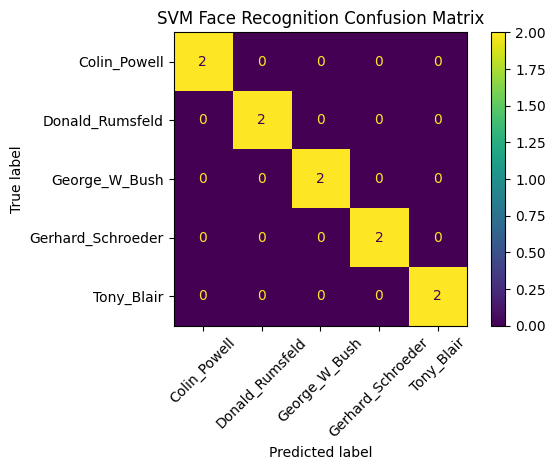

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=sorted(np.unique(y_test))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=sorted(np.unique(y_test))
)

disp.plot(
    xticks_rotation=45
)

plt.title("SVM Face Recognition Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

similarity_results = []

for item in test_data:

    test_embedding = item["Embedding"].reshape(1, -1)

    similarities = []

    for train_item in embedding_data:

        train_embedding = train_item["Embedding"].reshape(1, -1)

        score = cosine_similarity(
            test_embedding,
            train_embedding
        )[0][0]

        similarities.append({
            "Person": train_item["Person"],
            "Score": score
        })

    similarity_df = pd.DataFrame(similarities)

    best_match = similarity_df.loc[
        similarity_df["Score"].idxmax()
    ]

    similarity_results.append({
        "Filename": item["Filename"],
        "Actual": item["Actual"],
        "Predicted": best_match["Person"],
        "Similarity": best_match["Score"]
    })

similarity_results_df = pd.DataFrame(
    similarity_results
)

display(similarity_results_df)

,Filename,Actual,Predicted,Similarity
0,Colin_Powell_0005.jpg,Colin_Powell,Colin_Powell,0.807166
1,Colin_Powell_0004.jpg,Colin_Powell,Colin_Powell,0.773561
2,Donald_Rumsfeld_0005.jpg,Donald_Rumsfeld,Donald_Rumsfeld,0.647924
3,Donald_Rumsfeld_0004.jpg,Donald_Rumsfeld,Donald_Rumsfeld,0.712851
4,Gerhard_Schroeder_0005.jpg,Gerhard_Schroeder,Gerhard_Schroeder,0.791583
5,Gerhard_Schroeder_0004.jpg,Gerhard_Schroeder,Gerhard_Schroeder,0.785869
6,Tony_Blair_0005.jpg,Tony_Blair,Tony_Blair,0.690690
7,Tony_Blair_0004.jpg,Tony_Blair,Tony_Blair,0.694128
8,George_W_Bush_0004.jpg,George_W_Bush,George_W_Bush,0.612408
9,George_W_Bush_0005.jpg,George_W_Bush,George_W_Bush,0.752494


In [ ]:
cosine_accuracy = (
    similarity_results_df["Actual"]
    ==
    similarity_results_df["Predicted"]
).mean()

print(
    "Cosine Similarity Recognition Accuracy:",
    round(cosine_accuracy, 4)
)

Cosine Similarity Recognition Accuracy: 1.0


In [ ]:
from datetime import datetime

attendance_rows = []

current_time = datetime.now()

for _, row in similarity_results_df.iterrows():

    if row["Predicted"] != "UNKNOWN":

        attendance_rows.append({
            "Name": row["Predicted"],
            "Date": current_time.strftime("%Y-%m-%d"),
            "Time": current_time.strftime("%H:%M:%S"),
            "Similarity": round(
                float(row["Similarity"]),
                4
            )
        })

attendance_df = pd.DataFrame(
    attendance_rows
)

if len(attendance_df) > 0:

    attendance_df = attendance_df.drop_duplicates(
        subset=["Name", "Date"]
    )

attendance_path = (
    "/content/output/attendance.csv"
)

attendance_df.to_csv(
    attendance_path,
    index=False
)

print("Attendance saved to:")
print(attendance_path)

display(attendance_df)

Attendance saved to:
/content/output/attendance.csv


,Name,Date,Time,Similarity
0,Colin_Powell,2026-10-02,10:03:52,0.8072
2,Donald_Rumsfeld,2026-10-02,10:03:52,0.6479
4,Gerhard_Schroeder,2026-10-02,10:03:52,0.7916
6,Tony_Blair,2026-10-02,10:03:52,0.6907
8,George_W_Bush,2026-10-02,10:03:52,0.6124


In [ ]:
import sqlite3

DB_PATH = "/content/database/attendance.db"

connection = sqlite3.connect(DB_PATH)

cursor = connection.cursor()

cursor.execute("""
CREATE TABLE IF NOT EXISTS attendance (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    name TEXT,
    date TEXT,
    time TEXT,
    similarity REAL
)
""")

connection.commit()

for _, row in attendance_df.iterrows():

    cursor.execute("""
    INSERT INTO attendance
    (name, date, time, similarity)
    VALUES (?, ?, ?, ?)
    """, (
        row["Name"],
        row["Date"],
        row["Time"],
        row["Similarity"]
    ))

connection.commit()

print("Attendance written to database.")

Attendance written to database.


In [ ]:
database_df = pd.read_sql_query(
    """
    SELECT *
    FROM attendance
    """,
    connection
)

display(database_df)

,id,name,date,time,similarity
0,1,Colin_Powell,2026-10-02,10:03:52,0.8072
1,2,Donald_Rumsfeld,2026-10-02,10:03:52,0.6479
2,3,Gerhard_Schroeder,2026-10-02,10:03:52,0.7916
3,4,Tony_Blair,2026-10-02,10:03:52,0.6907
4,5,George_W_Bush,2026-10-02,10:03:52,0.6124


In [ ]:
if len(database_df) > 0:

    record_id = int(
        database_df.iloc[0]["id"]
    )

    cursor.execute("""
    UPDATE attendance
    SET similarity = ?
    WHERE id = ?
    """, (
        database_df.iloc[0]["similarity"],
        record_id
    ))

    connection.commit()

    print(
        "Database record modified successfully."
    )

Database record modified successfully.


In [ ]:
modified_df = pd.read_sql_query(
    """
    SELECT *
    FROM attendance
    """,
    connection
)

display(modified_df)

,id,name,date,time,similarity
0,1,Colin_Powell,2026-10-02,10:03:52,0.8072
1,2,Donald_Rumsfeld,2026-10-02,10:03:52,0.6479
2,3,Gerhard_Schroeder,2026-10-02,10:03:52,0.7916
3,4,Tony_Blair,2026-10-02,10:03:52,0.6907
4,5,George_W_Bush,2026-10-02,10:03:52,0.6124


In [ ]:
connection.close()

In [ ]:
selected_names = list(
    selected_people["Person"]
)

print("Known people:")
for name in selected_names:
    print("-", name)

Known people:
- George_W_Bush
- Colin_Powell
- Tony_Blair
- Donald_Rumsfeld
- Gerhard_Schroeder


In [ ]:
all_people = list(
    people_df["Person"]
)

unknown_candidates = [
    p for p in all_people
    if p not in selected_names
]

print(
    "Example unknown person:",
    unknown_candidates[0]
)

Example unknown person: Ariel_Sharon


In [ ]:
COSINE_THRESHOLD = 0.363

In [ ]:
thresholds = [
    0.30,
    0.35,
    0.363,
    0.40,
    0.45,
    0.50
]

for threshold in thresholds:

    accepted = (
        similarity_results_df["Similarity"]
        >= threshold
    )

    print(
        "Threshold:",
        threshold,
        "Accepted:",
        accepted.sum(),
        "Rejected:",
        (~accepted).sum()
    )

Threshold: 0.3 Accepted: 10 Rejected: 0
Threshold: 0.35 Accepted: 10 Rejected: 0
Threshold: 0.363 Accepted: 10 Rejected: 0
Threshold: 0.4 Accepted: 10 Rejected: 0
Threshold: 0.45 Accepted: 10 Rejected: 0
Threshold: 0.5 Accepted: 10 Rejected: 0


In [ ]:
final_results = pd.DataFrame({
    "Metric": [
        "Total Images",
        "Number of People",
        "Training Images",
        "Testing Images",
        "Successful Face Detections",
        "Failed Face Detections",
        "SVM Accuracy",
        "Cosine Similarity Accuracy"
    ],

    "Value": [
        len(eda_df),
        eda_df["Person"].nunique(),
        len(embedding_data),
        len(test_data),
        successful,
        failed,
        round(accuracy, 4),
        round(cosine_accuracy, 4)
    ]
})

display(final_results)

,Metric,Value
0,Total Images,25.0
1,Number of People,5.0
2,Training Images,15.0
3,Testing Images,10.0
4,Successful Face Detections,25.0
5,Failed Face Detections,0.0
6,SVM Accuracy,1.0
7,Cosine Similarity Accuracy,1.0


## Conclusion

A prototype face-attendance system was developed using the LFW public face dataset. YuNet was used for face detection and SFace was used to generate face embeddings. Exploratory Data Analysis was performed to study image distribution, lighting variation and face-detection failures.

The extracted face embeddings were reduced using PCA while retaining 95% of the variance. A linear SVM was then used for identity classification. Cosine similarity with a threshold was additionally used for embedding-based recognition and unknown-face rejection.

The recognized identities were recorded with date, time and similarity score in a CSV file and stored in an SQLite database. The database operations demonstrated include writing, reading and modifying records.

The system was evaluated using accuracy, precision, recall, F1-score and a confusion matrix. False acceptance and unknown-face rejection were also examined. Since the experiment uses a small public dataset, the system should be considered a prototype rather than a production classroom attendance system.